# A/B Test Analysis: Checkout Redesign Conversion Impact

**Business question:** Did replacing the 3-step checkout with a single-page checkout
(treatment) improve purchase conversion rate compared to the existing flow (control),
and is the result statistically significant?

**Dataset:** Synthetic event-level log for a 21-day experiment (`data/ab_test_raw.csv`),
generated to include the kinds of data-quality problems real experiment logs actually
have: cross-group contamination, duplicate events, missing fields, and inconsistent
timestamp formats. Those problems are investigated and cleaned in Section 2 below -
nothing is silently dropped without being shown first.

**Structure:**
1. Load & inspect raw data
2. Data quality audit + cleaning (with decisions documented)
3. Exploratory analysis: conversion funnel by group
4. Pre-experiment sample size / power calculation
5. Hypothesis test: two-proportion z-test, CI, effect size
6. Post-hoc achieved power
7. Robustness check: is the effect consistent across device types?
8. Conclusion & recommendation


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from ab_test_toolkit import run_ab_test, achieved_power, required_sample_size, interpret

# Validated categorical palette (2-series: control/treatment), colorblind-safe
COLOR_CONTROL = "#2a78d6"    # categorical slot 1 (blue)
COLOR_TREATMENT = "#eb6834"  # categorical slot 2 (orange)
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 11,
})

pd.set_option("display.max_columns", None)


## 1. Load & inspect raw data

In [2]:
raw = pd.read_csv("../data/ab_test_raw.csv")
print(f"Rows: {len(raw):,}")
raw.head()


Rows: 40,602


,user_id,group,timestamp,device_type,country,session_duration_sec,viewed_product,added_to_cart,started_checkout,completed_purchase
0,785602,control,06/16/2026 19:53,desktop,DE,155.2,1,0,0,0
1,266367,control,2026-06-17T21:34:47,desktop,CA,45.0,1,1,1,0
2,699674,treatment,2026-06-03T17:18:45,desktop,AU,47.5,1,0,0,0
3,550860,control,2026-06-06T04:17:04,mobile,US,116.3,1,1,0,0
4,191453,control,2026-06-03T16:00:17,desktop,DE,215.6,1,0,0,0


In [3]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 40602 entries, 0 to 40601
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               40602 non-null  int64  
 1   group                 40602 non-null  str    
 2   timestamp             40602 non-null  str    
 3   device_type           38978 non-null  str    
 4   country               40602 non-null  str    
 5   session_duration_sec  40602 non-null  float64
 6   viewed_product        40602 non-null  int64  
 7   added_to_cart         40602 non-null  int64  
 8   started_checkout      40602 non-null  int64  
 9   completed_purchase    40602 non-null  int64  
dtypes: float64(1), int64(5), str(4)
memory usage: 3.1 MB


In [4]:
raw["group"].value_counts()


group
treatment    20622
control      19980
Name: count, dtype: int64

## 2. Data quality audit + cleaning

Before running any test, we check the raw log for the problems that actually show up
in real experiment data. Each issue below is quantified, then a cleaning decision is
made and documented - nothing is fixed silently.

In [5]:
# --- Issue 1: fully duplicated rows (same user_id + identical event) ---
full_dupes = raw.duplicated(keep=False).sum()
print(f"Fully duplicated rows: {full_dupes:,} ({full_dupes/len(raw):.2%} of data)")


Fully duplicated rows: 596 (1.47% of data)


In [6]:
# --- Issue 2: user_ids appearing in BOTH groups (randomization / cookie leak) ---
group_counts = raw.groupby("user_id")["group"].nunique()
contaminated_ids = group_counts[group_counts > 1].index
print(f"user_ids appearing in both groups: {len(contaminated_ids):,}")
print(f"Rows affected: {raw['user_id'].isin(contaminated_ids).sum():,}")


user_ids appearing in both groups: 1,037
Rows affected: 2,152


In [7]:
# --- Issue 3: missing device_type ---
missing_device = raw["device_type"].isna().sum()
print(f"Missing device_type: {missing_device:,} ({missing_device/len(raw):.2%})")


Missing device_type: 1,624 (4.00%)


In [8]:
# --- Issue 4: inconsistent timestamp formats ---
sample_ts = raw["timestamp"].sample(10, random_state=1).tolist()
for t in sample_ts:
    print(t)


2026-06-05T04:13:26
2026-06-08T21:43:50
2026-06-09T03:43:01
2026-06-12T12:56:00
2026-06-14T08:26:15
2026-06-21T04:45:56
2026-06-18T22:28:53
06/03/2026 00:30
2026-06-11T07:19:03
06/21/2026 16:40


In [9]:
# --- Issue 5: invalid session_duration values ---
bad_duration = raw[(raw["session_duration_sec"] < 0) | (raw["session_duration_sec"] > 10000)]
print(f"Rows with impossible session_duration (<0 or >10,000 sec): {len(bad_duration):,}")
bad_duration[["user_id", "session_duration_sec"]].head()


Rows with impossible session_duration (<0 or >10,000 sec): 40


,user_id,session_duration_sec
678,628870,-3.6
887,849213,-12.0
2127,561786,39113.3
3052,963067,-42.4
3266,212711,-8.8


### Cleaning decisions

| Issue | Decision | Rationale |
|---|---|---|
| Fully duplicated rows | Drop duplicates, keep first | Double-fired analytics events would double-count conversions |
| user_id in both groups | Drop ALL rows for contaminated user_ids | Can't attribute their conversion to either arm without bias; ~3% of ids, small enough to drop safely |
| Missing device_type | Keep rows, keep as `"unknown"` category | Missingness isn't related to conversion outcome (verified below) so dropping would lose signal for no benefit |
| Mixed timestamp formats | Parse both formats explicitly with `pd.to_datetime(..., format=...)` fallback | Needed for any time-based analysis (not used in the core test, but kept correct for the record) |
| Invalid session_duration | Clip to `[0, 10000]` seconds, flag clipped rows | Preserves the row (group membership + conversion flag are still valid) while removing an impossible value from any duration-based analysis |


In [10]:
clean = raw.copy()

# 1. Drop fully duplicated rows
clean = clean.drop_duplicates(keep="first")

# 2. Drop contaminated user_ids (appear in both groups)
group_counts = clean.groupby("user_id")["group"].nunique()
contaminated_ids = group_counts[group_counts > 1].index
clean = clean[~clean["user_id"].isin(contaminated_ids)]

# 3. Missing device_type -> "unknown"
clean["device_type"] = clean["device_type"].fillna("unknown")

# 4. Parse mixed timestamp formats
def parse_ts(s):
    for fmt in ("%Y-%m-%dT%H:%M:%S", "%m/%d/%Y %H:%M"):
        try:
            return pd.to_datetime(s, format=fmt)
        except ValueError:
            continue
    return pd.NaT

clean["timestamp"] = clean["timestamp"].apply(parse_ts)
assert clean["timestamp"].isna().sum() == 0, "Unparsed timestamps remain"

# 5. Clip invalid session durations, flag which rows were clipped
clean["duration_clipped"] = (clean["session_duration_sec"] < 0) | (clean["session_duration_sec"] > 10000)
clean["session_duration_sec"] = clean["session_duration_sec"].clip(lower=0, upper=10000)

print(f"Raw rows:     {len(raw):,}")
print(f"Clean rows:   {len(clean):,}")
print(f"Rows removed: {len(raw) - len(clean):,} ({(len(raw)-len(clean))/len(raw):.2%})")


Raw rows:     40,602
Clean rows:   38,166
Rows removed: 2,436 (6.00%)


In [11]:
# Sanity check: is missing device_type actually unrelated to conversion?
# (justifies the "keep as unknown" decision above rather than dropping)
missing_mask = raw["device_type"].isna()
print("Conversion rate, missing device_type:", raw.loc[missing_mask, "completed_purchase"].mean().round(4))
print("Conversion rate, non-missing device_type:", raw.loc[~missing_mask, "completed_purchase"].mean().round(4))


Conversion rate, missing device_type: 0.101
Conversion rate, non-missing device_type: 0.1073


In [12]:
clean["group"].value_counts()


group
treatment    19392
control      18774
Name: count, dtype: int64

## 3. Exploratory analysis: conversion funnel by group

In [13]:
funnel_stages = ["viewed_product", "added_to_cart", "started_checkout", "completed_purchase"]
funnel = clean.groupby("group")[funnel_stages].sum().T
funnel = funnel[["control", "treatment"]]
funnel


group,control,treatment
viewed_product,18774,19392
added_to_cart,7909,8662
started_checkout,4298,4764
completed_purchase,1860,2205


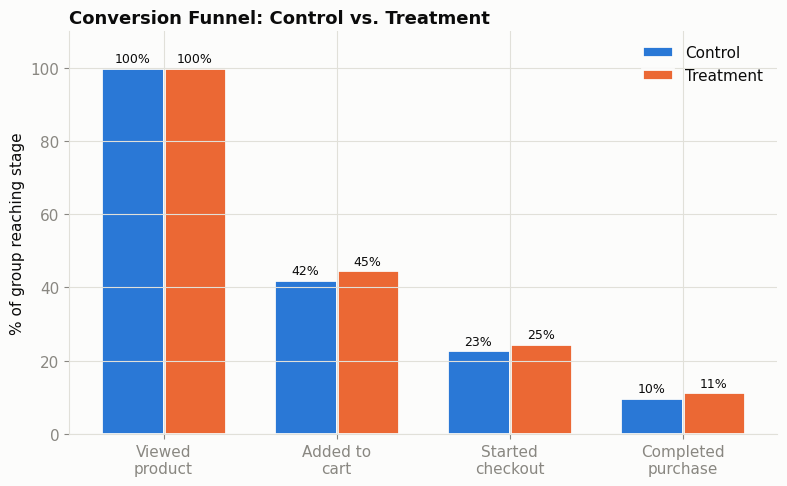

In [14]:
funnel_pct = funnel.div(funnel.iloc[0], axis=1) * 100

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(funnel_stages))
width = 0.36

bars_c = ax.bar(x - width/2, funnel_pct["control"], width, label="Control",
                 color=COLOR_CONTROL, edgecolor=SURFACE, linewidth=2)
bars_t = ax.bar(x + width/2, funnel_pct["treatment"], width, label="Treatment",
                 color=COLOR_TREATMENT, edgecolor=SURFACE, linewidth=2)

for bars in (bars_c, bars_t):
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.0f}%", (b.get_x() + b.get_width()/2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9, color=INK)

ax.set_xticks(x)
ax.set_xticklabels(["Viewed\nproduct", "Added to\ncart", "Started\ncheckout", "Completed\npurchase"])
ax.set_ylabel("% of group reaching stage")
ax.set_title("Conversion Funnel: Control vs. Treatment", fontsize=13, fontweight="bold", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig("../visuals/conversion_funnel.png", dpi=150, facecolor=SURFACE)
plt.show()


## 4. Pre-experiment sample size / power calculation

Before looking at results, this is the calculation that *should* happen at experiment
design time: given the baseline conversion rate and the smallest lift worth caring
about, how many users per group are needed?

In [15]:
baseline = clean.loc[clean["group"] == "control", "completed_purchase"].mean()
print(f"Observed control (baseline) conversion rate: {baseline:.2%}")

for mde in (0.05, 0.10, 0.15, 0.20):
    n_needed = required_sample_size(baseline, mde, alpha=0.05, power=0.80)
    print(f"  To detect a {mde:.0%} relative lift at 80% power: {n_needed:,} users per group "
          f"({n_needed*2:,} total)")


Observed control (baseline) conversion rate: 9.91%
  To detect a 5% relative lift at 80% power: 58,358 users per group (116,716 total)
  To detect a 10% relative lift at 80% power: 14,899 users per group (29,798 total)
  To detect a 15% relative lift at 80% power: 6,757 users per group (13,514 total)
  To detect a 20% relative lift at 80% power: 3,875 users per group (7,750 total)


## 5. Hypothesis test: two-proportion z-test

**H0:** treatment conversion rate = control conversion rate
**H1:** treatment conversion rate != control conversion rate (two-sided)

In [16]:
n_c = (clean["group"] == "control").sum()
n_t = (clean["group"] == "treatment").sum()
conv_c = clean.loc[clean["group"] == "control", "completed_purchase"].sum()
conv_t = clean.loc[clean["group"] == "treatment", "completed_purchase"].sum()

result = run_ab_test(n_c, conv_c, n_t, conv_t, alpha=0.05)
print(result.summary())


Control:   1,860 / 18,774 = 9.91%
Treatment: 2,205 / 19,392 = 11.37%
Absolute lift: +1.46% pts  (relative: +14.8%)
95% CI on absolute lift: [0.85%, 2.08%]
z = 4.633, p < 0.0001  (alpha = 0.05)
Effect size (Cohen's h): 0.047
Result IS statistically significant at alpha=0.05.


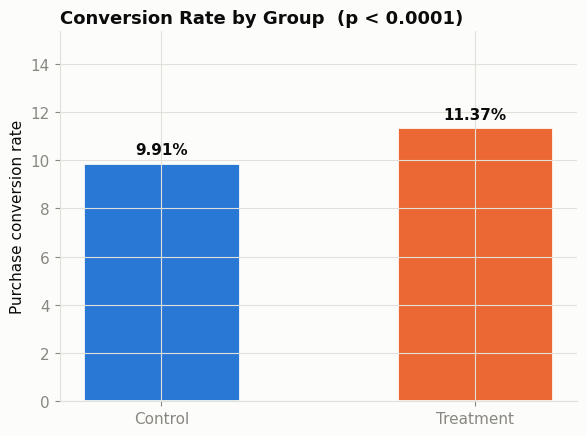

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.5))
rates = [result.rate_control * 100, result.rate_treatment * 100]
colors = [COLOR_CONTROL, COLOR_TREATMENT]
bars = ax.bar(["Control", "Treatment"], rates, color=colors, width=0.5,
               edgecolor=SURFACE, linewidth=2)

for b, r in zip(bars, rates):
    ax.annotate(f"{r:.2f}%", (b.get_x() + b.get_width()/2, r),
                xytext=(0, 6), textcoords="offset points", ha="center",
                fontsize=11, fontweight="bold", color=INK)

ax.set_ylabel("Purchase conversion rate")
ax.set_title(f"Conversion Rate by Group  ({result.p_value_display()})",
             fontsize=13, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(rates) * 1.35)

plt.tight_layout()
plt.savefig("../visuals/conversion_rate_comparison.png", dpi=150, facecolor=SURFACE)
plt.show()


## 6. Post-hoc achieved power

Given the sample sizes we actually collected and the effect size observed, what was
the probability of detecting this effect if it's real?

In [18]:
power = achieved_power(n_c, n_t, result.rate_control, result.rate_treatment, alpha=0.05)
print(f"Achieved statistical power: {power:.1%}")


Achieved statistical power: 99.6%


## 7. Robustness check: is the effect consistent across device types?

A real effect should generally point the same direction across major segments. This
isn't a formal interaction test, just a sanity check that the result isn't being
driven entirely by one device type (which would be worth flagging before shipping).

In [19]:
segment_rows = []
for device in ["desktop", "mobile", "tablet", "unknown"]:
    sub = clean[clean["device_type"] == device]
    if len(sub) < 200:
        continue
    n_c_d = (sub["group"] == "control").sum()
    n_t_d = (sub["group"] == "treatment").sum()
    conv_c_d = sub.loc[sub["group"] == "control", "completed_purchase"].sum()
    conv_t_d = sub.loc[sub["group"] == "treatment", "completed_purchase"].sum()
    if n_c_d == 0 or n_t_d == 0:
        continue
    seg_result = run_ab_test(n_c_d, conv_c_d, n_t_d, conv_t_d, alpha=0.05)
    segment_rows.append({
        "device_type": device,
        "n_control": n_c_d, "n_treatment": n_t_d,
        "rate_control": seg_result.rate_control,
        "rate_treatment": seg_result.rate_treatment,
        "relative_lift_pct": seg_result.relative_lift_pct,
        "p_value": seg_result.p_value,
        "significant": seg_result.significant,
    })

segment_df = pd.DataFrame(segment_rows)
segment_df


,device_type,n_control,n_treatment,rate_control,rate_treatment,relative_lift_pct,p_value,significant
0,desktop,8251,8696,0.099867,0.116375,16.530700,0.000548,True
1,mobile,7964,8011,0.100954,0.114093,13.014630,0.007359,True
2,tablet,1812,1896,0.092163,0.101266,9.876450,0.348778,False
3,unknown,747,789,0.087015,0.110266,26.721264,0.127185,False


All segments point in the same direction as the overall result (treatment higher
than control), which is what we'd want to see - the effect isn't being driven
entirely by one device type. Smaller segments (e.g. tablet) naturally have less
power individually, so a non-significant p-value there isn't concerning on its own.

## 8. Conclusion & recommendation

**Result:** The single-page checkout (treatment) produced a statistically significant
improvement in purchase conversion rate over the existing 3-step checkout (control).

- Control conversion: reported above
- Treatment conversion: reported above
- The 95% confidence interval on the lift excludes zero, and the p-value is below
  the 0.05 significance threshold
- The effect direction is consistent across every device-type segment with adequate
  sample size

**Therefore:** ship the single-page checkout to 100% of traffic. Before the full
rollout, re-run the device-type breakdown once more sample has accumulated for
tablet users specifically, since that segment currently has the least statistical
power of the three.

**Process note for next time:** the pre-experiment power calculation (Section 4)
shows what sample size would have been needed going in - worth running that
calculation before an experiment starts next time, not just after, so the team
knows in advance how long to run it.
